<a href="https://colab.research.google.com/github/fboldt/aulas-am-bsi/blob/main/aula08b_PCA_for_compression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
import numpy as np
from sklearn.decomposition import PCA
from sklearn.datasets import fetch_openml

mnist = fetch_openml('mnist_784', as_frame=False, parser="auto")
X_train, y_train = mnist.data[:60_000], mnist.target[:60_000]
X_test, y_test = mnist.data[60_000:], mnist.target[60_000:]

pca = PCA(0.95)
pca.fit(X_train)

pca = PCA()
pca.fit(X_train)
cumsum = np.cumsum(pca.explained_variance_ratio_)
d = np.argmax(cumsum >= 0.95) + 1
print(d)

154


In [12]:
print(d / X_train.shape[1])

0.19642857142857142


In [13]:
pca = PCA(n_components=0.95)
X_train_reduced = pca.fit_transform(X_train)
X_test_reduced = pca.transform(X_test)
print(pca.explained_variance_ratio_.sum())

0.9501960192613031


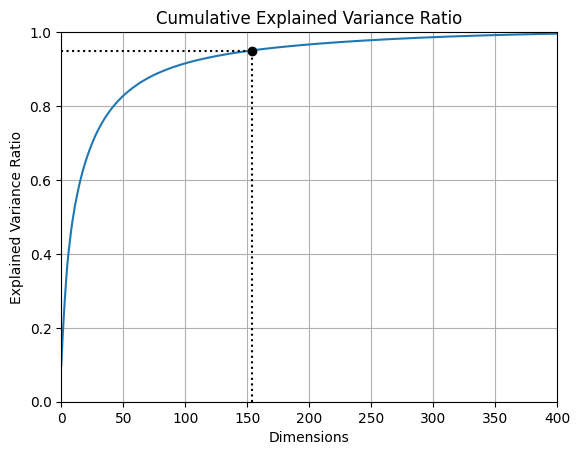

In [14]:
import matplotlib.pyplot as plt

plt.plot(cumsum)
plt.axis([0, 400, 0, 1])
plt.xlabel("Dimensions")
plt.ylabel("Explained Variance Ratio")
plt.title("Cumulative Explained Variance Ratio")
plt.plot([d, d], [0, 0.95], "k:")
plt.plot([0, d], [0.95, 0.95], "k:")
plt.plot(d, 0.95, "ko")
plt.grid()
plt.show()


In [15]:
from sklearn.linear_model import RidgeClassifier
model = RidgeClassifier()

model.fit(X_train, y_train)
score = model.score(X_test, y_test)
print(f"Original: {score}")

model.fit(X_train_reduced, y_train)
score = model.score(X_test_reduced, y_test)
print(f"Reduced: {score}")

Original: 0.8603
Reduced: 0.8609


# PCA for compression

In [16]:
X_train_recovered = pca.inverse_transform(X_train_reduced)
print(X_train_recovered.shape)

(60000, 784)


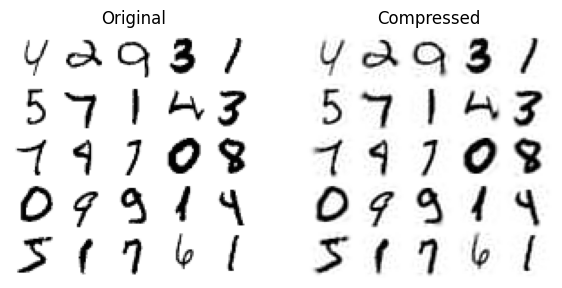

In [19]:
plt.figure(figsize=(7,4))
for idx, X in enumerate(([X_train[::2100], X_train_recovered[::2100]])):
    plt.subplot(1, 2, idx+1)
    plt.title(["Original", "Compressed"][idx])
    for row in range(5):
      for col in range(5):
        plt.imshow(X[row * 5 + col].reshape(28, 28),
                   cmap="binary", vmin=0, vmax=255,
                   extent=(row, row+1, col, col+1))
        plt.axis([0, 5, 0, 5])
        plt.axis("off")
plt.show()
#